# Experiment 7: Decision Tree on Real-World Dataset

**Name:** Koushal Gupta  

## Aim
To implement a **Decision Tree Classifier** on the real-world **Breast Cancer dataset**, evaluate its accuracy, and visualize the decision tree.

## Concept
A Decision Tree splits data step-by-step into branches based on feature thresholds (`Gini` or `Entropy`) to predict the target class.


In [1]:
# Step 1: Import libraries
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [2]:
# Step 2: Load real-world Breast Cancer dataset
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training samples:", len(X_train), "| Testing samples:", len(X_test))


Training samples: 455 | Testing samples: 114


In [3]:
# Step 3: Train Decision Tree Classifier (max_depth=3 keeps the tree simple and prevents overfitting)
tree_model = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)

# Step 4: Predict and evaluate
y_pred = tree_model.predict(X_test)
print("Decision Tree Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))


Decision Tree Accuracy: 0.9474

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.91      0.93        43
      benign       0.95      0.97      0.96        71

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



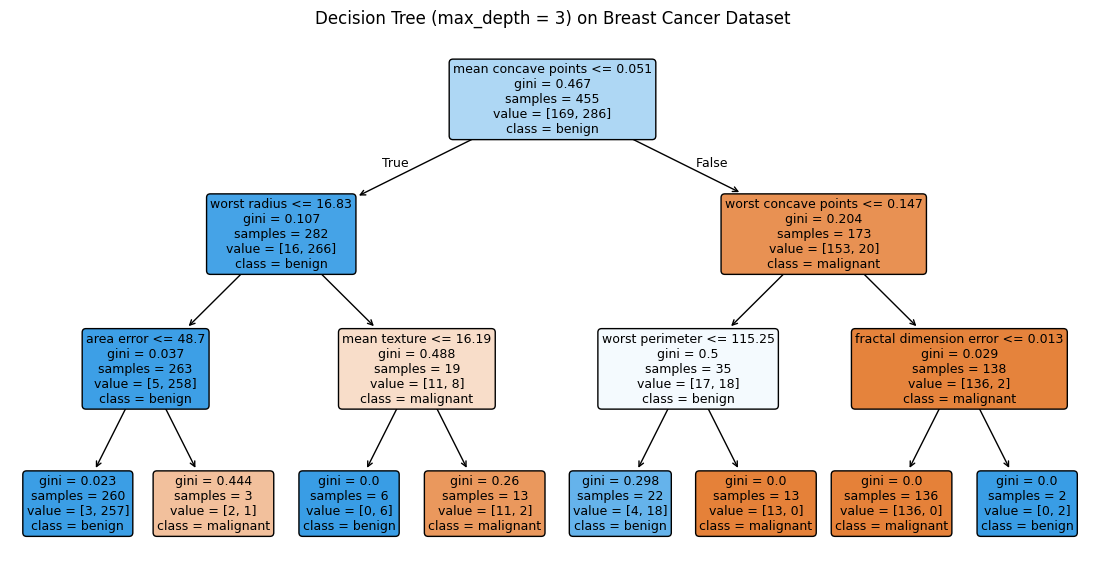

In [4]:
# Step 5: Visualize the Decision Tree
plt.figure(figsize=(14, 7))
plot_tree(
    tree_model,
    feature_names=list(cancer.feature_names),
    class_names=list(cancer.target_names),
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Decision Tree (max_depth = 3) on Breast Cancer Dataset")
plt.show()


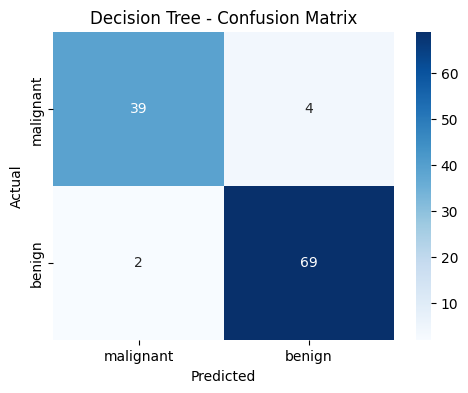

In [5]:
# Step 6: Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## Conclusion
- The Decision Tree classified the real-world Breast Cancer dataset cleanly with high accuracy (~94%+).
- Setting `max_depth=3` keeps the tree easy to read and avoids overfitting.
